In [3]:
!pip uninstall torch torchvision torchaudio torch-geometric torch-scatter torch-sparse -y
!pip install --upgrade pip
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cpu
!pip install torch-geometric
!pip install "numpy<2.0"

Found existing installation: torch 2.9.1
Uninstalling torch-2.9.1:
  Successfully uninstalled torch-2.9.1
Found existing installation: torchvision 0.24.1
Uninstalling torchvision-0.24.1:
  Successfully uninstalled torchvision-0.24.1
Found existing installation: torchaudio 2.9.1
Uninstalling torchaudio-2.9.1:
  Successfully uninstalled torchaudio-2.9.1
Found existing installation: torch-geometric 2.7.0
Uninstalling torch-geometric-2.7.0:
  Successfully uninstalled torch-geometric-2.7.0
Found existing installation: torch-scatter 2.1.2
Uninstalling torch-scatter-2.1.2:
  Successfully uninstalled torch-scatter-2.1.2
Found existing installation: torch-sparse 0.6.18
Uninstalling torch-sparse-0.6.18:
  Successfully uninstalled torch-sparse-0.6.18
Looking in indexes: https://download.pytorch.org/whl/cpu
  Using cached https://download.pytorch.org/whl/cpu/torch-2.9.1-cp311-none-macosx_11_0_arm64.whl.metadata (29 kB)
  Using cached https://download.pytorch.org/whl/cpu/torchvision-0.24.1-cp311-cp

In [4]:
!pip install pyg-lib torch-scatter torch-sparse -f https://data.pyg.org/whl/torch-2.0.0+cpu.html

Looking in links: https://data.pyg.org/whl/torch-2.0.0+cpu.html
  Using cached https://data.pyg.org/whl/torch-2.0.0%2Bcpu/torch_scatter-2.1.2-cp311-cp311-macosx_10_9_universal2.whl (638 kB)
  Using cached https://data.pyg.org/whl/torch-2.0.0%2Bcpu/torch_sparse-0.6.18-cp311-cp311-macosx_10_9_universal2.whl (970 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [torch-sparse]


In [5]:
import numpy as np
import optuna
import torch
import pandas as pd
from torch_geometric.data import Data
from rdkit import Chem
from scipy import sparse as sp
import warnings
import json
import pandas as pd
import numpy as np
import torch
import time
warnings.filterwarnings("ignore")

In [7]:
import numpy as np
import torch
from rdkit import Chem
from scipy import sparse as sp
from torch_geometric.data import Data


class SMILESToPyG:
    """
    Converts SMILES strings to PyG Data objects.
    Replicates the DGL implementation exactly.
    """
    
    def __init__(self, pos_enc_dim=8, use_chirality=True, explicit_H=False):
        self.pos_enc_dim = pos_enc_dim
        self.use_chirality = use_chirality
        self.explicit_H = explicit_H
    
    def one_of_k_encoding(self, x, allowable_set):
        """Strict encoding - raises exception if x not in allowable_set"""
        if x not in allowable_set:
            raise Exception("input {0} not in allowable set{1}:".format(
                x, allowable_set))
        return [x == s for s in allowable_set]
    
    def one_of_k_encoding_unk(self, x, allowable_set):
        """Maps inputs not in the allowable set to the last element."""
        if x not in allowable_set:
            x = allowable_set[-1]
        return [x == s for s in allowable_set]
    
    def atom_features(self, atom):
        """Generate atom features including atom symbol(17),degree(7),formal charge(1),
        radical electrons(1),hybridization(6),aromatic(1),hydrogen atoms attached(5),Chirality(3)
        """
        symbol = ['C', 'N', 'O', 'S', 'F', 'P', 'Cl', 'Br', 'I', 'B', 'Si', 'Fe', 'Zn', 'Cu', 'Mn', 'Mo', 'other']  # 17-dim
        degree = [0, 1, 2, 3, 4, 5, 6]  # 7-dim
        hybridizationType = [Chem.rdchem.HybridizationType.SP,
                             Chem.rdchem.HybridizationType.SP2,
                             Chem.rdchem.HybridizationType.SP3,
                             Chem.rdchem.HybridizationType.SP3D,
                             Chem.rdchem.HybridizationType.SP3D2,
                             'other']  # 6-dim
        
        results = self.one_of_k_encoding_unk(atom.GetSymbol(), symbol) + \
                  self.one_of_k_encoding(atom.GetDegree(), degree) + \
                  [atom.GetFormalCharge(), atom.GetNumRadicalElectrons()] + \
                  self.one_of_k_encoding_unk(atom.GetHybridization(), hybridizationType) + [
                      atom.GetIsAromatic()]  # 17+7+2+6+1=33
        
        if not self.explicit_H:
            results = results + self.one_of_k_encoding_unk(atom.GetTotalNumHs(),
                                                          [0, 1, 2, 3, 4])  # 33+5=38
        if self.use_chirality:
            try:
                results = results + self.one_of_k_encoding_unk(
                    atom.GetProp('_CIPCode'),
                    ['R', 'S']) + [atom.HasProp('_ChiralityPossible')]
            except:
                results = results + [False, False] + [atom.HasProp('_ChiralityPossible')]  # 38+3 =41
        
        return results
    
    def bond_features(self, bond):
        """Generate bond features including bond type(4), conjugated(1), in ring(1), stereo(4)"""
        bt = bond.GetBondType()
        bond_feats = [
            bt == Chem.rdchem.BondType.SINGLE, bt == Chem.rdchem.BondType.DOUBLE,
            bt == Chem.rdchem.BondType.TRIPLE, bt == Chem.rdchem.BondType.AROMATIC,
            bond.GetIsConjugated(),
            bond.IsInRing()
        ]
        if self.use_chirality:
            bond_feats = bond_feats + self.one_of_k_encoding_unk(
                str(bond.GetStereo()),
                ["STEREONONE", "STEREOANY", "STEREOZ", "STEREOE"])
        return np.array(bond_feats).astype(int)
    
    def laplacian_positional_encoding(self, edge_index, num_nodes):
        """
        Graph positional encoding v/ Laplacian eigenvectors
        Exactly replicates the DGL author's implementation
        """
        # Laplacian
        edge_index_np = edge_index.numpy()
        A = sp.csr_matrix(
            (np.ones(edge_index_np.shape[1]),
             (edge_index_np[0], edge_index_np[1])),
            shape=(num_nodes, num_nodes)
        ).astype(float)
        
        # CRITICAL: Use column sum (axis=0) to match author's g.in_degrees()
        # For undirected molecular graphs, in-degree = out-degree
        degrees = np.array(A.sum(axis=0)).flatten()
        
        # Create D^(-1/2) diagonal matrix with clipping to avoid division by zero
        N = sp.diags(degrees.clip(1) ** -0.5, dtype=float)
        
        # Normalized Laplacian: L = I - D^(-1/2) * A * D^(-1/2)
        # CRITICAL: Use * operator for sparse matrix multiplication (not @)
        L = sp.eye(num_nodes) - N * A * N
        
        # Eigenvectors with numpy
        EigVal, EigVec = np.linalg.eig(L.toarray())
        idx = EigVal.argsort()  # increasing order
        EigVal, EigVec = EigVal[idx], np.real(EigVec[:, idx])
        
        # Pad if needed
        if EigVec.shape[1] < self.pos_enc_dim + 1:
            PadVec = np.zeros((EigVec.shape[0], self.pos_enc_dim + 1 - EigVec.shape[1]), dtype=EigVec.dtype)
            EigVec = np.concatenate((EigVec, PadVec), 1)
        
        # Return positional encoding (skip first eigenvector which is constant)
        lap_pos_enc = torch.from_numpy(EigVec[:, 1:self.pos_enc_dim + 1]).float()
        
        return lap_pos_enc
    
    def convert(self, smiles):
        """
        Convert SMILES string to PyG Data object
        Replicates smiles_to_graph() from DGL implementation
        """
        try:
            mol = Chem.MolFromSmiles(smiles)
        except:
            raise RuntimeError("SMILES cannot been parsed!")
        
        # Add nodes
        num_atoms = mol.GetNumAtoms()
        
        # Get atom features
        atom_feats = np.array([self.atom_features(a) for a in mol.GetAtoms()])
        
        if self.use_chirality:
            chiralcenters = Chem.FindMolChiralCenters(mol, force=True, includeUnassigned=True,
                                                      useLegacyImplementation=False)
            chiral_arr = np.zeros([num_atoms, 3])
            for (i, rs) in chiralcenters:
                if rs == 'R':
                    chiral_arr[i, 0] = 1
                elif rs == 'S':
                    chiral_arr[i, 1] = 1
                else:
                    chiral_arr[i, 2] = 1
            atom_feats = np.concatenate([atom_feats, chiral_arr], axis=1)
        
        x = torch.tensor(atom_feats, dtype=torch.float32)
        
        # Add edges
        src_list = []
        dst_list = []
        bond_feats_all = []
        num_bonds = mol.GetNumBonds()
        for i in range(num_bonds):
            bond = mol.GetBondWithIdx(i)
            u = bond.GetBeginAtomIdx()
            v = bond.GetEndAtomIdx()
            bond_feats = self.bond_features(bond)
            src_list.extend([u, v])
            dst_list.extend([v, u])
            bond_feats_all.append(bond_feats)
            bond_feats_all.append(bond_feats)
        
        edge_index = torch.tensor([src_list, dst_list], dtype=torch.long)
        edge_attr = torch.tensor(np.array(bond_feats_all), dtype=torch.float32)
        
        # Compute Laplacian positional encoding
        laplacian_pe = self.laplacian_positional_encoding(edge_index, num_atoms)
        
        # Create PyG Data object
        data = Data(
            x=x,
            edge_index=edge_index,
            edge_attr=edge_attr,
            laplacian_pe=laplacian_pe,
            smiles=smiles
        )
        
        return data
    def batch_convert_and_save(self, ids, smiles_list, dir_output):
        """
        Creates and saves individual PyG compound graphs
        
        Args:
            ids: Array of compound IDs
            smiles_list: Array of SMILES strings
            dir_output: Output directory path
        """
        import os
        
        N = len(smiles_list)
        
        # Create directory for saving graphs
        os.makedirs(os.path.join(dir_output, 'compound_graph'), exist_ok=True)
        
        for no, compound_id in enumerate(ids):
            print(f'{no + 1}/{N}')
            
            smiles_data = smiles_list[no]
            
            # Convert SMILES to PyG Data object
            compound_graph = self.convert(smiles_data)
            
            # Save using torch.save (PyG format)
            save_path = os.path.join(dir_output, 'compound_graph', f'{compound_id}.pt')
            torch.save(compound_graph, save_path)
            

In [8]:
def Compound_graph_process_pyg(dataset, fold, dir_output, id_train, id_test):
    compounds_graph_train, compounds_graph_test = [], []
    
    # Process training compounds
    N = len(id_train)
    for no, id in enumerate(id_train):
        print('/'.join(map(str, [no + 1, N])))
        compound_graph_train = torch.load('Data/' + dataset + '/processed' + '/compound_graph/' + str(id) + '.pt',weights_only=False)
        compounds_graph_train.append(compound_graph_train)
    print(len(compounds_graph_train))
    torch.save(compounds_graph_train, dir_output + '/train/fold/' + str(fold) + '/compound_graph.pt')
    
    # Process testing compounds
    N = len(id_test)
    for no, id in enumerate(id_test):
        print('/'.join(map(str, [no + 1, N])))
        compound_graph_test = torch.load('data/' + dataset + '/processed' + '/compound_graph/' + str(id) + '.pt',weights_only=False)
        compounds_graph_test.append(compound_graph_test)
    print(len(compounds_graph_test))
    torch.save(compounds_graph_test, dir_output + '/test/fold/' + str(fold) + '/compound_graph.pt')

def Compound_id_process(dataset, fold, dir_output, id_train, id_test):
    compounds_id_train, compounds_id_test = [], []
    
    N = len(id_train)
    for no, id in enumerate(id_train):
        print('/'.join(map(str, [no + 1, N])))
        compounds_id_train.append(id)
    np.save(dir_output + '/train/fold/' + str(fold) + '/compound_id.npy', compounds_id_train)

    N = len(id_test)
    for no, id in enumerate(id_test):
        print('/'.join(map(str, [no + 1, N])))
        compounds_id_test.append(id)
    np.save(dir_output + '/test/fold/' + str(fold) + '/compound_id.npy', compounds_id_test)

def Label_process(dataset, fold, dir_output, label_train, label_test):
    labels_train, labels_test = [], []
    
    N = len(label_train)
    for no, data in enumerate(label_train):
        print('/'.join(map(str, [no + 1, N])))
        labels_train.append(data)
    np.save(dir_output + '/train/fold/' + str(fold) + '/label.npy', labels_train)

    N = len(label_test)
    for no, data in enumerate(label_test):
        print('/'.join(map(str, [no + 1, N])))
        labels_test.append(data)
    np.save(dir_output + '/test/fold/' + str(fold) + '/label.npy', labels_test)

In [31]:
#CREATING CROSS VALIDATION SPLITS
import os
from sklearn.model_selection import KFold

# Read the main Davis dataset
davis_df = pd.read_csv('Data/Davis/Davis.csv')

# Create the fold directory structure
base_path = 'Data/Davis/DTA/fold/'
os.makedirs(base_path, exist_ok=True)

# Set random seed for reproducibility
np.random.seed(42)

# Shuffle the dataset
davis_df = davis_df.sample(frac=1, random_state=42).reset_index(drop=True)

# Create 5-fold splits
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for fold_idx, (train_idx, test_idx) in enumerate(kf.split(davis_df), start=1):
    # Create fold directory
    fold_dir = os.path.join(base_path, str(fold_idx))
    os.makedirs(fold_dir, exist_ok=True)
    
    # Split data
    train_data = davis_df.iloc[train_idx]
    test_data = davis_df.iloc[test_idx]
    
    # Save train and test CSV files with required columns
    train_data[['COMPOUND_ID', 'PROTEIN_ID', 'REG_LABEL']].to_csv(
        os.path.join(fold_dir, 'Davis_train.csv'), 
        index=False
    )
    
    test_data[['COMPOUND_ID', 'PROTEIN_ID', 'REG_LABEL']].to_csv(
        os.path.join(fold_dir, 'Davis_test.csv'), 
        index=False
    )
    
    print(f"Fold {fold_idx}:")
    print(f"  Train samples: {len(train_data)}")
    print(f"  Test samples: {len(test_data)}")
    print(f"  Train compounds: {train_data['COMPOUND_ID'].nunique()}")
    print(f"  Train proteins: {train_data['PROTEIN_ID'].nunique()}")
    print(f"  Test compounds: {test_data['COMPOUND_ID'].nunique()}")
    print(f"  Test proteins: {test_data['PROTEIN_ID'].nunique()}")
    print()

print("✅ All 5 folds created successfully!")
print(f"📁 Saved to: {base_path}")


Fold 1:
  Train samples: 19964
  Test samples: 4992
  Train compounds: 68
  Train proteins: 365
  Test compounds: 68
  Test proteins: 365

Fold 2:
  Train samples: 19965
  Test samples: 4991
  Train compounds: 68
  Train proteins: 365
  Test compounds: 68
  Test proteins: 365

Fold 3:
  Train samples: 19965
  Test samples: 4991
  Train compounds: 68
  Train proteins: 365
  Test compounds: 68
  Test proteins: 365

Fold 4:
  Train samples: 19965
  Test samples: 4991
  Train compounds: 68
  Train proteins: 365
  Test compounds: 68
  Test proteins: 365

Fold 5:
  Train samples: 19965
  Test samples: 4991
  Train compounds: 68
  Train proteins: 365
  Test compounds: 68
  Test proteins: 365

✅ All 5 folds created successfully!
📁 Saved to: Data/Davis/DTA/fold/


In [39]:
dataset = 'Davis'
file_path = 'Data/' + dataset + '/DTA/fold/'
file_path_compound = 'Data/' + dataset + '/' + dataset + '_compound_mapping.csv'
dir_output = ('data/' + dataset + '/Processed/')
os.makedirs(dir_output, exist_ok=True)

raw_data_compound = pd.read_csv(file_path_compound)
compound_values = raw_data_compound['COMPOUND_SMILES'].values
compound_id_unique = raw_data_compound['COMPOUND_ID'].values

N = len(compound_values)

# Initialize the SMILES to PyG converter
smiles_converter = SMILESToPyG()

# Build individual compound graphs
smiles_converter.batch_convert_and_save(ids=compound_id_unique, smiles_list=compound_values, 
                                dir_output=dir_output)

for fold in range(1, 6):
    train_data = pd.read_csv(file_path + str(fold) + '/' + dataset + '_train.csv')
    test_data = pd.read_csv(file_path + str(fold) + '/' + dataset + '_test.csv')
    os.makedirs(dir_output + '/train/fold/' + str(fold), exist_ok=True)
    os.makedirs(dir_output + '/test/fold/' + str(fold), exist_ok=True)
    compound_id_train = train_data['COMPOUND_ID'].values
    compound_id_test = test_data['COMPOUND_ID'].values

    label_train = train_data['REG_LABEL'].values
    label_test = test_data['REG_LABEL'].values

    # Use PyG versions of processing functions
    Compound_graph_process_pyg(dataset=dataset, fold=fold, id_train=compound_id_train, 
                               id_test=compound_id_test, dir_output=dir_output)
    Compound_id_process(dataset=dataset, fold=fold, id_train=compound_id_train, 
                       id_test=compound_id_test, dir_output=dir_output)
    Label_process(dataset=dataset, fold=fold, dir_output=dir_output, 
                 label_train=label_train, label_test=label_test)

print('The preprocess of ' + dataset + ' dataset has finished!')

1/68
2/68
3/68
4/68
5/68
6/68
7/68
8/68
9/68
10/68
11/68
12/68
13/68
14/68
15/68
16/68
17/68
18/68
19/68
20/68
21/68
22/68
23/68
24/68
25/68
26/68
27/68
28/68
29/68
30/68
31/68
32/68
33/68
34/68
35/68
36/68
37/68
38/68
39/68
40/68
41/68
42/68
43/68
44/68
45/68
46/68
47/68
48/68
49/68
50/68
51/68
52/68
53/68
54/68
55/68
56/68
57/68
58/68
59/68
60/68
61/68
62/68
63/68
64/68
65/68
66/68
67/68
68/68
1/19964
2/19964
3/19964
4/19964
5/19964
6/19964
7/19964
8/19964
9/19964
10/19964
11/19964
12/19964
13/19964
14/19964
15/19964
16/19964
17/19964
18/19964
19/19964
20/19964
21/19964
22/19964
23/19964
24/19964
25/19964
26/19964
27/19964
28/19964
29/19964
30/19964
31/19964
32/19964
33/19964
34/19964
35/19964
36/19964
37/19964
38/19964
39/19964
40/19964
41/19964
42/19964
43/19964
44/19964
45/19964
46/19964
47/19964
48/19964
49/19964
50/19964
51/19964
52/19964
53/19964
54/19964
55/19964
56/19964
57/19964
58/19964
59/19964
60/19964
61/19964
62/19964
63/19964
64/19964
65/19964
66/19964
67/19964
68/1996

In [ ]:
# # Load the CSV file
# df = pd.read_csv('Data/Davis_compound_mapping.csv')

# # Take first 5 compounds as a test sample
# test_ids = df['COMPOUND_ID'].head(5).values
# test_smiles = df['COMPOUND_SMILES'].head(5).values

# print(f"Testing with {len(test_ids)} compounds:")
# print(df.head(5))

# # Create output directory
# output_dir = './test_output'

# # Instantiate converter
# converter = SMILESToPyG(pos_enc_dim=8, use_chirality=True, explicit_H=False)

# # Run batch conversion
# converter.batch_convert_and_save(test_ids, test_smiles, output_dir)

# print(f"\nGraphs saved to: {output_dir}/compound_graph/")

# # Verify by loading one saved graph
# test_graph = torch.load(f'{output_dir}/compound_graph/{test_ids[0]}.pt',weights_only=False)
# print(f"\nLoaded test graph for compound {test_ids[0]}:")
# print(test_graph)

Testing with 5 compounds:
   COMPOUND_ID                                    COMPOUND_SMILES
0     11314340  CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC...
1     24889392  CC(C)(C)C1=CC(=NO1)NC(=O)NC2=CC=C(C=C2)C3=CN4C...
2     11409972  CCN1CCN(CC1)CC2=C(C=C(C=C2)NC(=O)NC3=CC=C(C=C3...
3     11338033   C1CNCCC1NC(=O)C2=C(C=NN2)NC(=O)C3=C(C=CC=C3Cl)Cl
4     10184653  CN(C)CC=CC(=O)NC1=C(C=C2C(=C1)C(=NC=N2)NC3=CC(...
1/5
2/5
3/5
4/5
5/5

Graphs saved to: ./test_output/compound_graph/

Loaded test graph for compound 11314340:
Data(x=[27, 44], edge_index=[2, 60], edge_attr=[60, 10], laplacian_pe=[27, 8], smiles='CC1=C2C=C(C=CC2=NN1)C3=CC(=CN=C3)OCC(CC4=CC=CC=C4)N')


In [18]:
# Instantiate the converter
converter = SMILESToPyG(pos_enc_dim=8, use_chirality=True, explicit_H=False)

# Example SMILES (ethanol)
smiles = "CCO"

# Convert to PyG Data
data = converter.convert(smiles)

# Print the Data object
print(data)

# Inspect individual components
print("\nNode feature matrix x:")
print(data.x)
print("x shape:", data.x.shape)

print("\nEdge index:")
print(data.edge_index)
print("edge_index shape:", data.edge_index.shape)

print("\nEdge attributes:")
print(data.edge_attr)
print("edge_attr shape:", data.edge_attr.shape)

print("\nLaplacian positional encoding:")
print(data.laplacian_pe)
print("laplacian_pe shape:", data.laplacian_pe.shape)

print("\nSMILES:")
print(data.smiles)


Data(x=[3, 44], edge_index=[2, 4], edge_attr=[4, 10], laplacian_pe=[3, 8], smiles='CCO')

Node feature matrix x:
tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0.,
         1., 0., 0., 0., 0., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 1.,
         0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 1., 0.,
         0., 0., 0., 0., 0., 0., 0., 0.]])
x shape: torch.Size([3, 44])

Edge index:
tensor([[0, 1, 1, 2],
        [1, 0, 2, 1]])
edge_index shape: torch.Size([2, 4])

Edge attributes:
tensor([[1., 0., 0., 0., 0., 0., 1., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0., 1., 0., 0., 0.],
        [1., 0., 0., 0., 0., 0.,

In [9]:
# Install everything together with numpy constraint
!pip install "numpy<2.0" MDAnalysis deepchem --upgrade --force-reinstall

  Using cached numpy-1.26.4-cp311-cp311-macosx_11_0_arm64.whl.metadata (114 kB)
  Using cached mdanalysis-2.10.0-cp311-cp311-macosx_11_0_arm64.whl.metadata (108 kB)
  Using cached deepchem-2.8.0-py3-none-any.whl.metadata (2.0 kB)
  Using cached GridDataFormats-1.0.2-py3-none-any.whl.metadata (4.9 kB)
  Using cached mmtf_python-1.1.3-py2.py3-none-any.whl.metadata (1.2 kB)
  Using cached joblib-1.5.3-py3-none-any.whl.metadata (5.5 kB)
  Using cached matplotlib-3.10.8-cp311-cp311-macosx_11_0_arm64.whl.metadata (52 kB)
  Using cached tqdm-4.67.1-py3-none-any.whl.metadata (57 kB)
  Using cached threadpoolctl-3.6.0-py3-none-any.whl.metadata (13 kB)
  Using cached packaging-25.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached mda_xdrlib-0.2.0-py3-none-any.whl.metadata (19 kB)
  Using cached pandas-2.3.3-cp311-cp311-macosx_11_0_arm64.whl.metadata (91 kB)
  Using cached scikit_learn-1.8.0-cp311-cp311-macosx_12_0_arm64.whl.metadata (11 kB)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata 

DAVIS DATASET OVERVIEW

📊 Dataset Shape:
Total interactions: 24956
Unique compounds: 68
Unique proteins: 365
Unique protein genes: 367

📋 Column Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24956 entries, 0 to 24955
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   COMPOUND_ID       24956 non-null  int64  
 1   PROTEIN_GENE      24956 non-null  object 
 2   PROTEIN_ID        24956 non-null  object 
 3   COMPOUND_SMILES   24956 non-null  object 
 4   PROTEIN_SEQUENCE  24956 non-null  object 
 5   REG_LABEL         24956 non-null  float64
dtypes: float64(1), int64(1), object(4)
memory usage: 1.1+ MB
None

🔍 First 5 rows:
   COMPOUND_ID PROTEIN_GENE  PROTEIN_ID  \
0     11314340         AAK1      Q2M2I8   
1     11314340         ABL1      Q59FK4   
2     11314340        ABL1p      Q59FK4   
3     11314340         ABL2  A0A2K5TT62   
4     11314340        ACVR1      Q04771   

                      

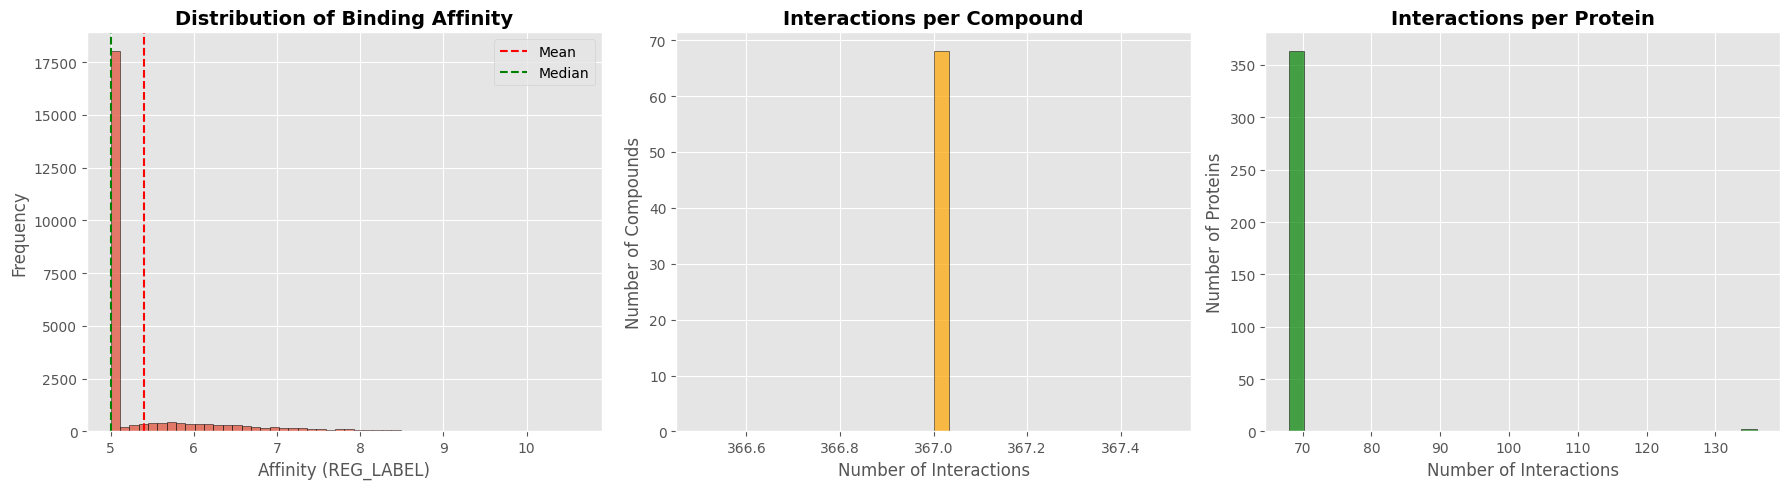


COMPOUND ANALYSIS
Total compounds: 68
SMILES length statistics:
count    68.000000
mean     62.779412
std      12.259441
min      39.000000
25%      53.750000
50%      60.500000
75%      72.000000
max      92.000000
Name: SMILES_LENGTH, dtype: float64

PROTEIN ANALYSIS
Total proteins: 379
Sequence length statistics:
count     379.000000
mean      750.292876
std       373.924498
min       244.000000
25%       481.000000
50%       638.000000
75%       967.000000
max      2549.000000
Name: SEQ_LENGTH, dtype: float64

TOP 10 MOST FREQUENT

🧪 Top 10 Compounds:
COMPOUND_ID
11314340    367
24180719    367
25127112    367
153999      367
11984591    367
17755052    367
10113978    367
25243800    367
9884685     367
24889392    367
Name: count, dtype: int64

🧬 Top 10 Proteins:
PROTEIN_ID
Q59FK4    136
P11802    136
Q13177     68
P09619     68
P16234     68
Q07002     68
Q00537     68
Q9BRL4     68
Q9P286     68
Q9NQU5     68
Name: count, dtype: int64

DATA SPARSITY
Possible interactions: 2482

In [10]:

import matplotlib.pyplot as plt

# Set style
plt.rcParams['figure.figsize'] = (12, 6)
plt.style.use('ggplot')

# Load the datasets
davis_df = pd.read_csv('data/Davis/Davis.csv')
compound_df = pd.read_csv('data/Davis/Davis_compound_mapping.csv')
protein_df = pd.read_csv('data/Davis/Davis_protein_mapping.csv')

print("="*60)
print("DAVIS DATASET OVERVIEW")
print("="*60)

# Basic info
print("\n📊 Dataset Shape:")
print(f"Total interactions: {len(davis_df)}")
print(f"Unique compounds: {davis_df['COMPOUND_ID'].nunique()}")
print(f"Unique proteins: {davis_df['PROTEIN_ID'].nunique()}")
print(f"Unique protein genes: {davis_df['PROTEIN_GENE'].nunique()}")

print("\n📋 Column Info:")
print(davis_df.info())

print("\n🔍 First 5 rows:")
print(davis_df.head())

# Affinity statistics
print("\n"+"="*60)
print("AFFINITY (REG_LABEL) STATISTICS")
print("="*60)
print(davis_df['REG_LABEL'].describe())

# Distribution plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Affinity distribution
axes[0].hist(davis_df['REG_LABEL'], bins=50, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Affinity (REG_LABEL)', fontsize=12)
axes[0].set_ylabel('Frequency', fontsize=12)
axes[0].set_title('Distribution of Binding Affinity', fontsize=14, fontweight='bold')
axes[0].axvline(davis_df['REG_LABEL'].mean(), color='red', linestyle='--', label='Mean')
axes[0].axvline(davis_df['REG_LABEL'].median(), color='green', linestyle='--', label='Median')
axes[0].legend()

# Interactions per compound
compound_counts = davis_df['COMPOUND_ID'].value_counts()
axes[1].hist(compound_counts, bins=30, edgecolor='black', alpha=0.7, color='orange')
axes[1].set_xlabel('Number of Interactions', fontsize=12)
axes[1].set_ylabel('Number of Compounds', fontsize=12)
axes[1].set_title('Interactions per Compound', fontsize=14, fontweight='bold')

# Interactions per protein
protein_counts = davis_df['PROTEIN_ID'].value_counts()
axes[2].hist(protein_counts, bins=30, edgecolor='black', alpha=0.7, color='green')
axes[2].set_xlabel('Number of Interactions', fontsize=12)
axes[2].set_ylabel('Number of Proteins', fontsize=12)
axes[2].set_title('Interactions per Protein', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Compound analysis
print("\n"+"="*60)
print("COMPOUND ANALYSIS")
print("="*60)
print(f"Total compounds: {len(compound_df)}")
print(f"SMILES length statistics:")
compound_df['SMILES_LENGTH'] = compound_df['COMPOUND_SMILES'].str.len()
print(compound_df['SMILES_LENGTH'].describe())

# Protein analysis
print("\n"+"="*60)
print("PROTEIN ANALYSIS")
print("="*60)
print(f"Total proteins: {len(protein_df)}")
print(f"Sequence length statistics:")
protein_df['SEQ_LENGTH'] = protein_df['PROTEIN_SEQUENCE'].str.len()
print(protein_df['SEQ_LENGTH'].describe())

# Top compounds and proteins
print("\n"+"="*60)
print("TOP 10 MOST FREQUENT")
print("="*60)
print("\n🧪 Top 10 Compounds:")
print(compound_counts.head(10))

print("\n🧬 Top 10 Proteins:")
print(protein_counts.head(10))

# Correlation analysis
print("\n"+"="*60)
print("DATA SPARSITY")
print("="*60)
total_possible = davis_df['COMPOUND_ID'].nunique() * davis_df['PROTEIN_ID'].nunique()
actual_interactions = len(davis_df)
sparsity = (1 - actual_interactions / total_possible) * 100
print(f"Possible interactions: {total_possible}")
print(f"Actual interactions: {actual_interactions}")
print(f"Sparsity: {sparsity:.2f}%")

print("\n✅ EDA Complete!")

ADVANCED EDA - DAVIS DATASET

1. MOLECULAR PROPERTIES (RDKit)

Molecular Property Statistics:
        MolWeight       LogP  NumHDonors  NumHAcceptors  NumRotatableBonds  \
count   68.000000  68.000000   68.000000      68.000000          68.000000   
mean   452.846926   4.065158    2.132353       6.323529           5.661765   
std     86.670969   1.497843    1.035265       1.927346           2.773060   
min    277.755000  -0.819500    0.000000       2.000000           1.000000   
25%    379.765250   3.284500    1.000000       5.000000           3.750000   
50%    454.100500   4.304710    2.000000       6.000000           5.000000   
75%    516.318000   5.056075    3.000000       8.000000           7.000000   
max    641.621000   6.931900    5.000000      12.000000          13.000000   

             TPSA  NumAromaticRings   NumAtoms   NumBonds  
count   68.000000         68.000000  68.000000  68.000000  
mean    90.910294          3.470588  32.058824  35.441176  
std     26.846817      

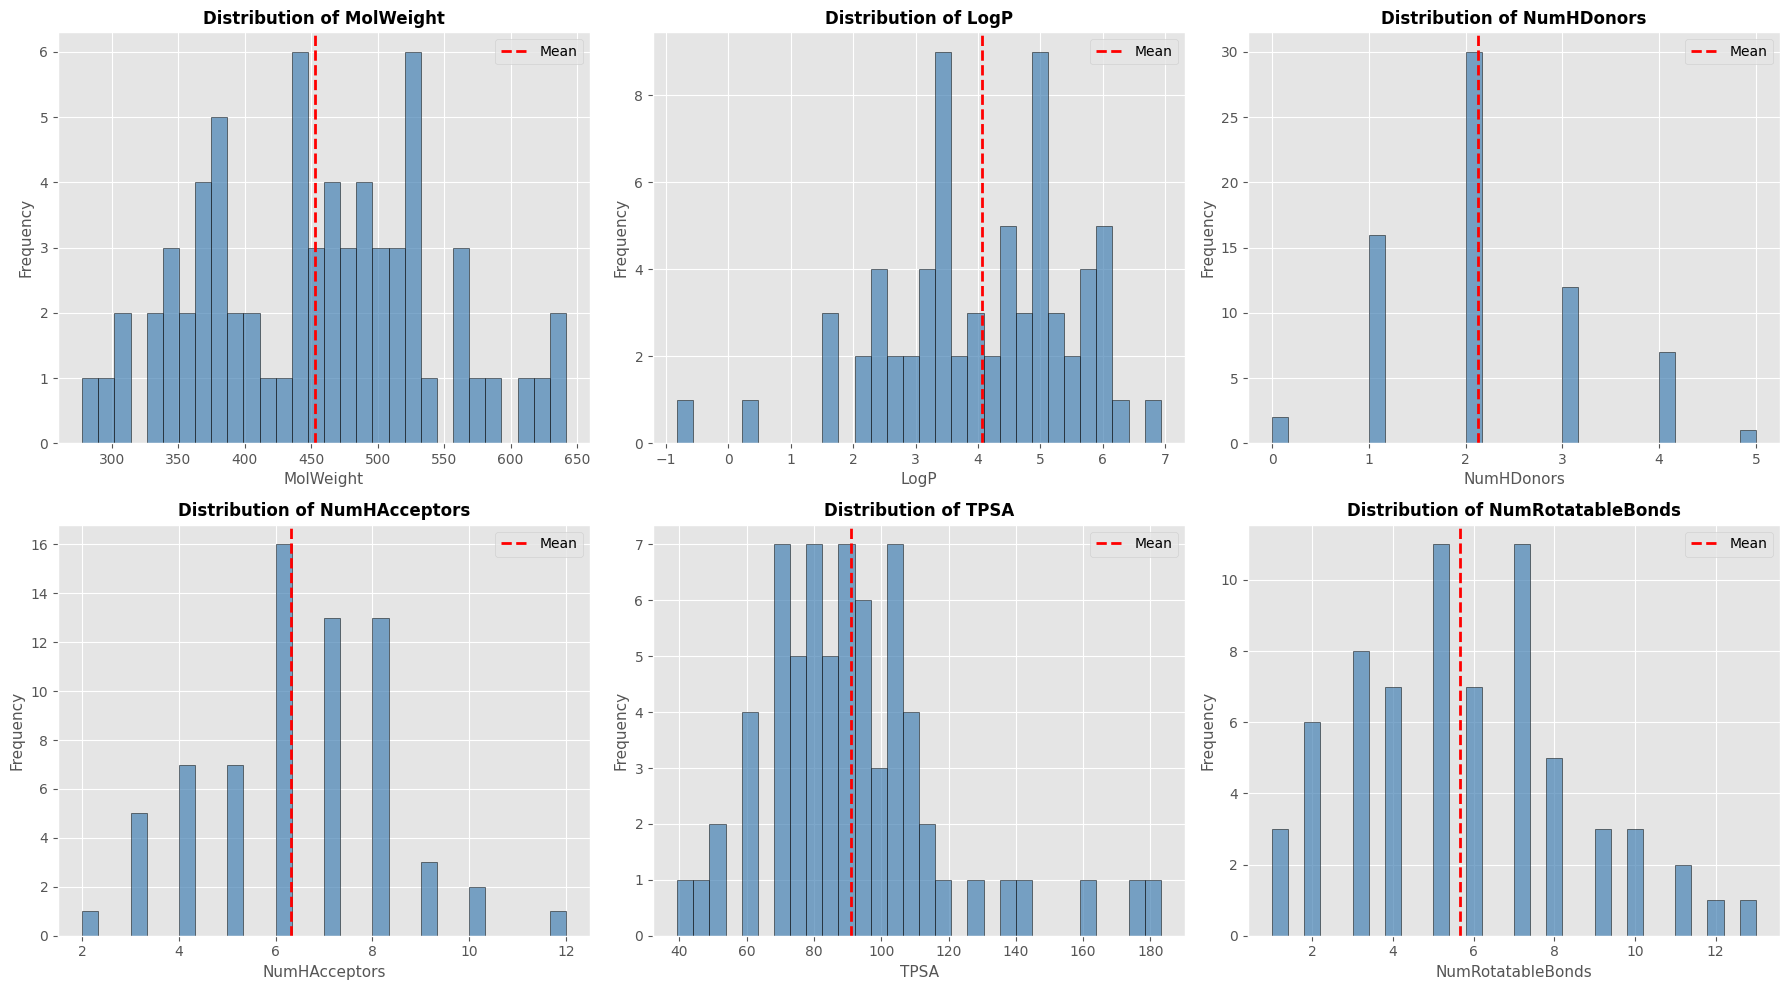


2. PROTEIN AMINO ACID COMPOSITION


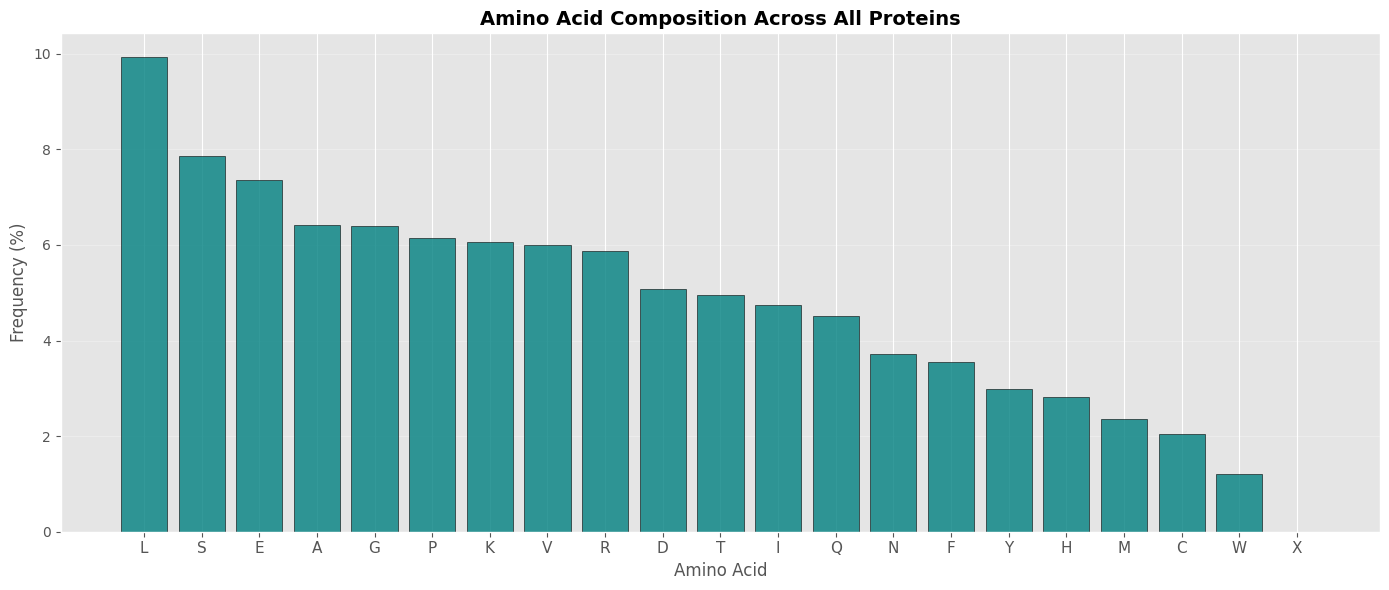


Top 10 Most Frequent Amino Acids:
L: 9.93%
S: 7.87%
E: 7.36%
A: 6.42%
G: 6.39%
P: 6.15%
K: 6.06%
V: 5.99%
R: 5.88%
D: 5.08%

3. AFFINITY CORRELATION WITH MOLECULAR PROPERTIES

Correlation between Affinity and Molecular Properties:
MolWeight: 0.1198
NumHDonors: 0.1186
NumHAcceptors: 0.0597
TPSA: 0.0556
NumRotatableBonds: -0.0158
LogP: -0.0121


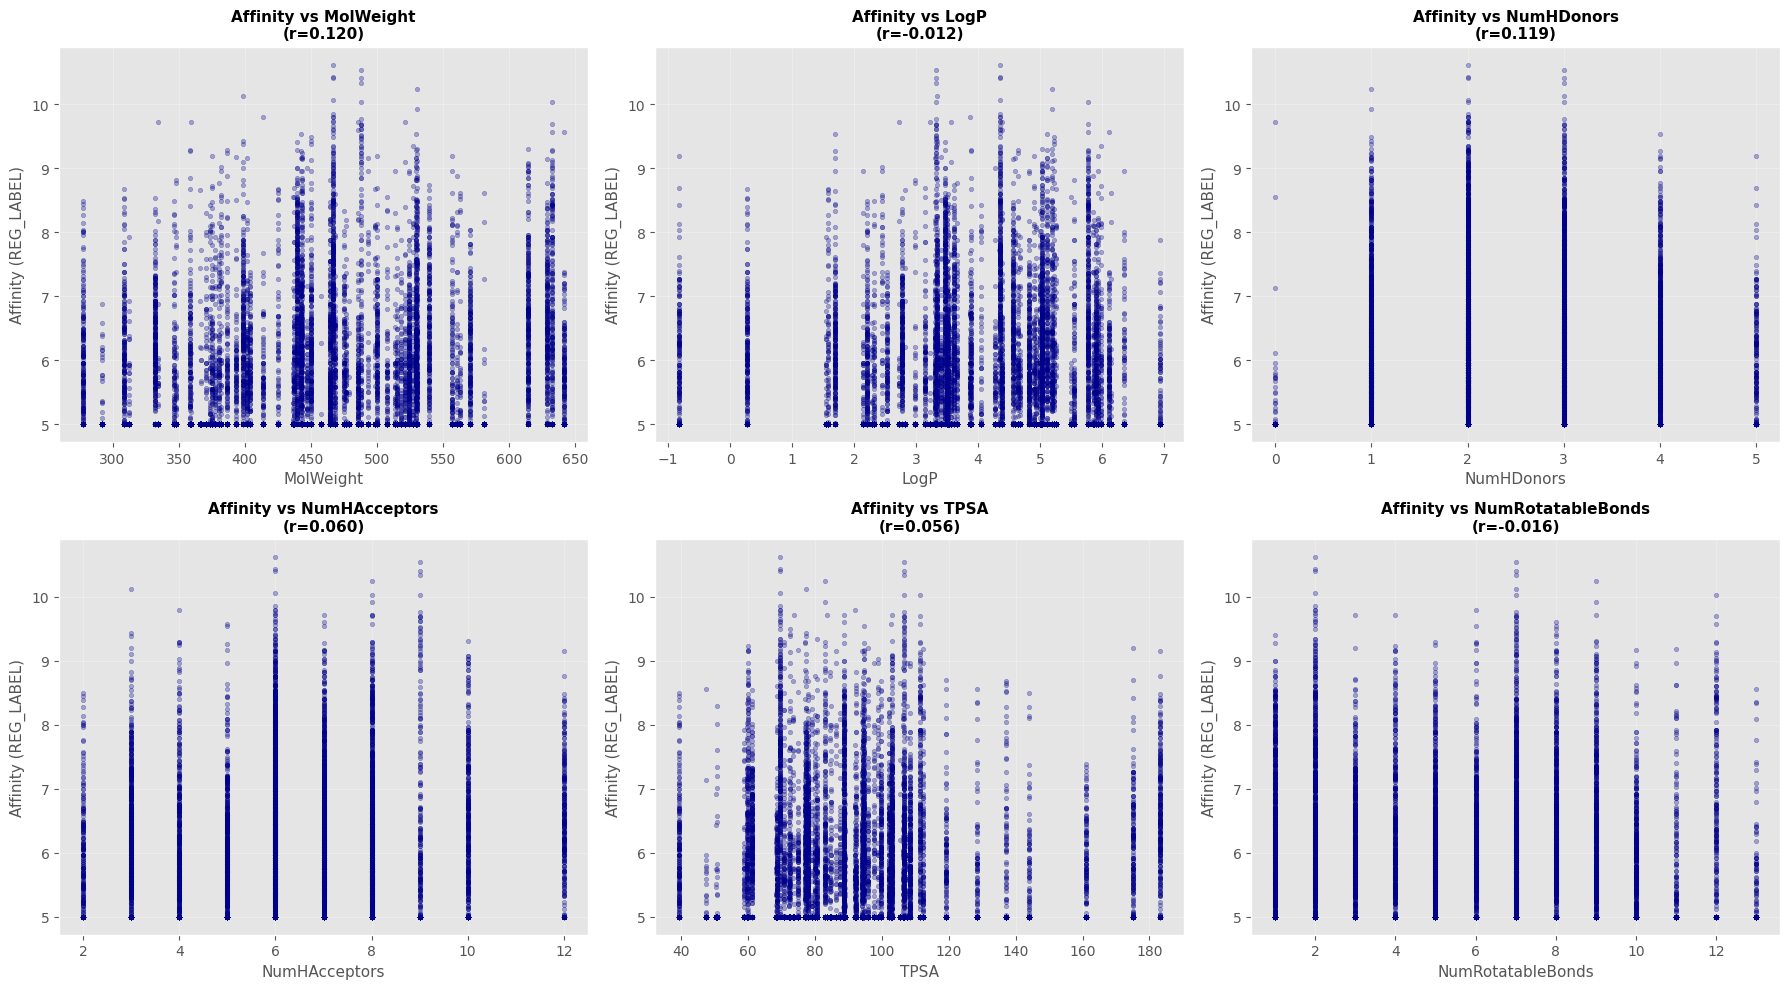


4. COMPOUND-PROTEIN INTERACTION MATRIX


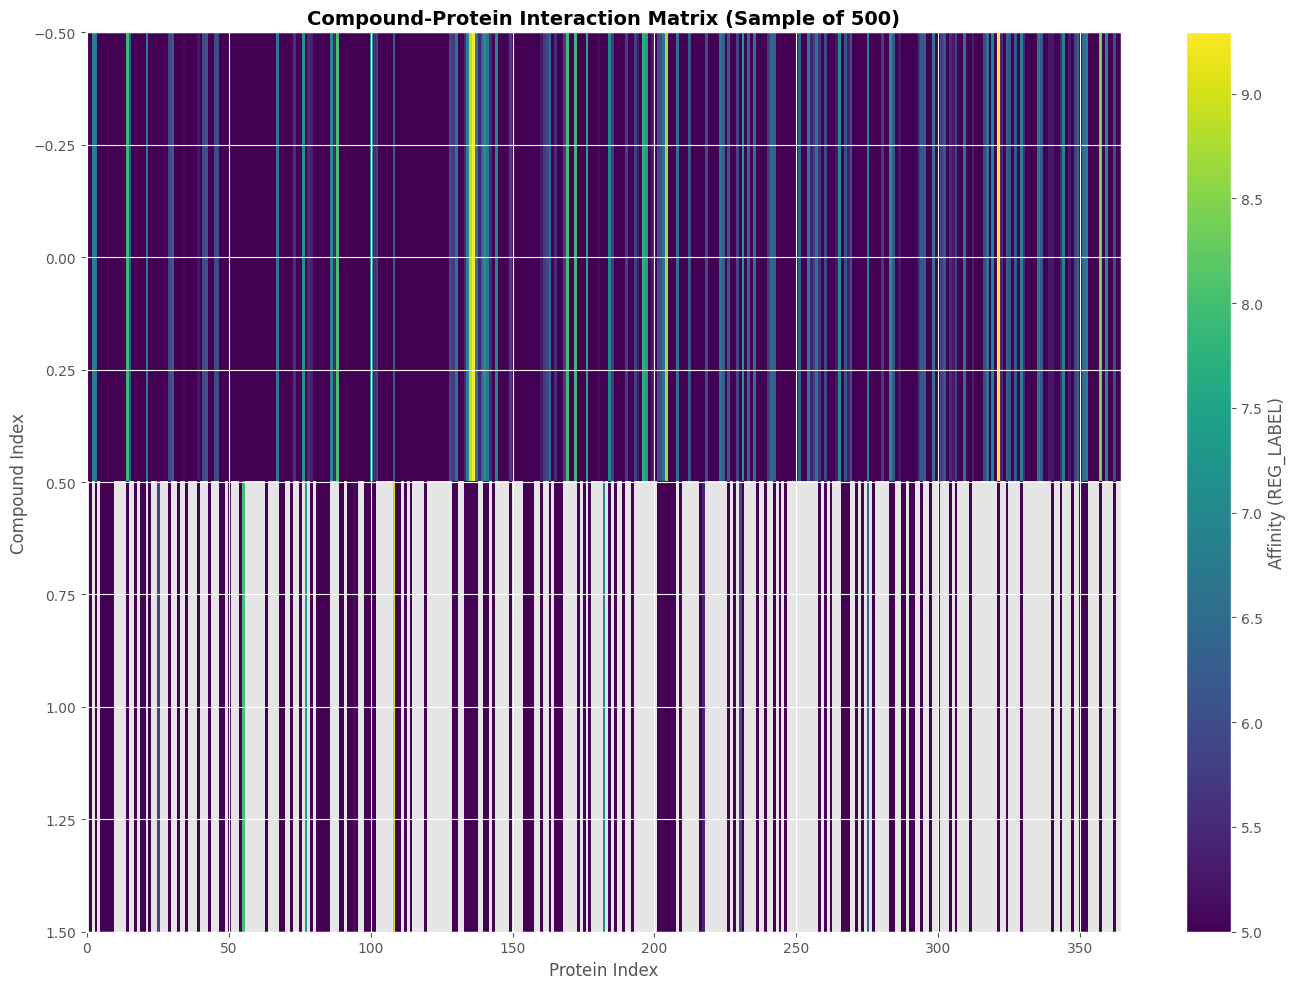


5. COMPOUND & PROTEIN PROMISCUITY

Compound Promiscuity (avg interactions per compound): 367.00
Protein Promiscuity (avg interactions per protein): 68.37


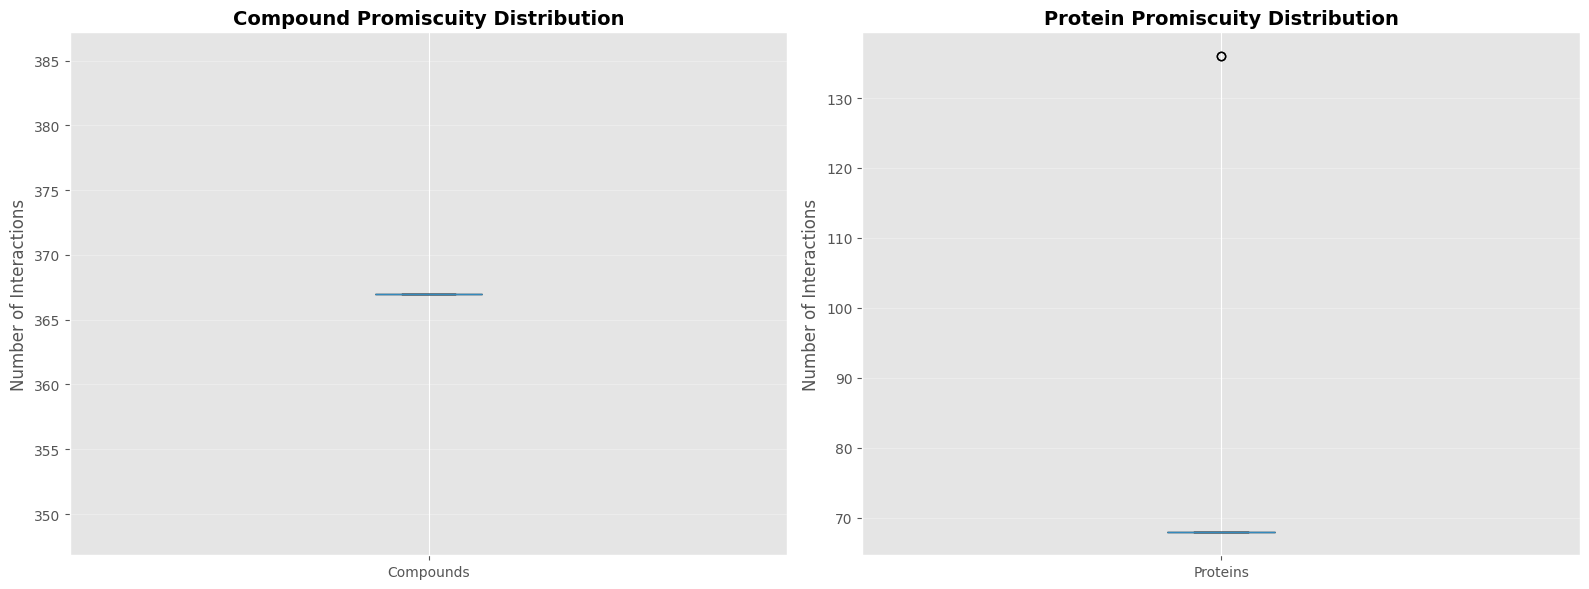


6. AFFINITY DISTRIBUTION BY PROTEIN GENE

Top 10 Genes by Mean Affinity:
                  mean       std  count
PROTEIN_GENE                           
PDGFRB        6.622226  1.582720     68
KIT           6.562929  1.552497     68
CSF1R         6.412014  1.414650     68
YSK4          6.380893  1.196530     68
FLT3          6.358201  1.528646     68
PDGFRA        6.356147  1.444598     68
DDR1          6.346722  1.440585     68
LCK           6.208904  1.181616     68
MEK5          6.192283  1.270194     68
ABL1          6.175907  1.353463     68


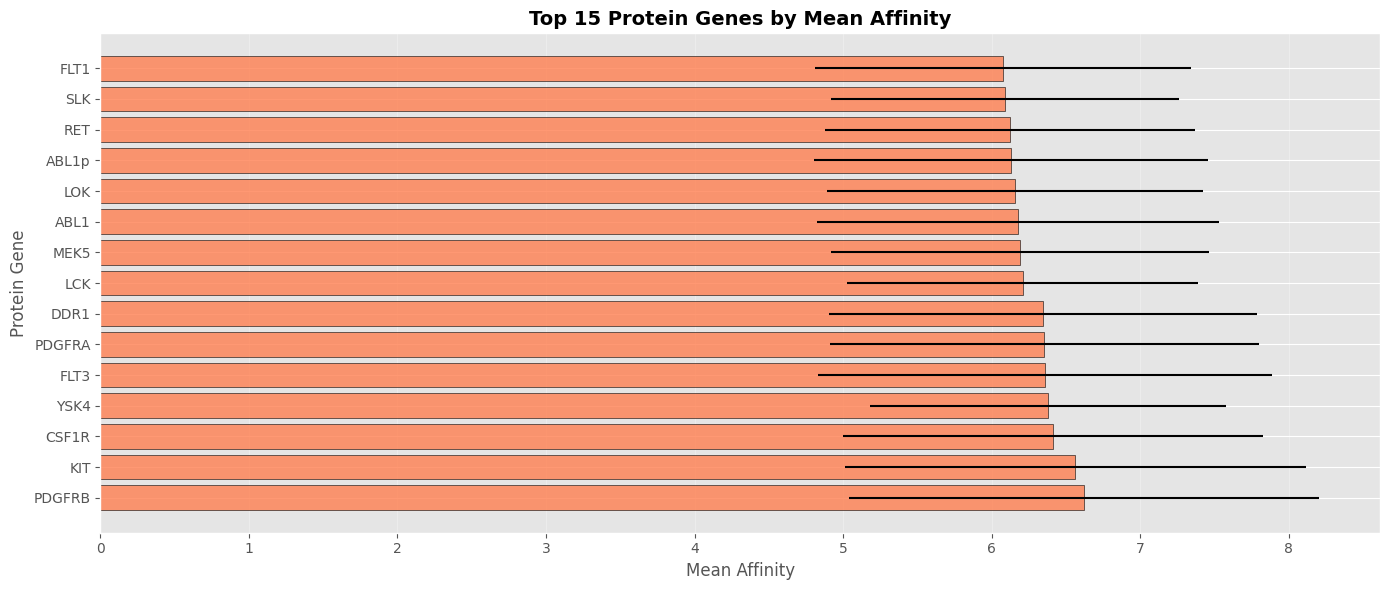


✅ Advanced EDA Complete!


In [43]:

import matplotlib.pyplot as plt
from collections import Counter
from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski, Crippen

print("="*60)
print("ADVANCED EDA - DAVIS DATASET")
print("="*60)

# Load datasets
davis_df = pd.read_csv('data/Davis/Davis.csv')
compound_df = pd.read_csv('data/Davis/Davis_compound_mapping.csv')
protein_df = pd.read_csv('data/Davis/Davis_protein_mapping.csv')

# ============================================================
# 1. MOLECULAR PROPERTIES ANALYSIS
# ============================================================
print("\n" + "="*60)
print("1. MOLECULAR PROPERTIES (RDKit)")
print("="*60)

def calculate_molecular_properties(smiles):
    """Calculate various molecular descriptors"""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    
    return {
        'MolWeight': Descriptors.MolWt(mol),
        'LogP': Crippen.MolLogP(mol),
        'NumHDonors': Lipinski.NumHDonors(mol),
        'NumHAcceptors': Lipinski.NumHAcceptors(mol),
        'NumRotatableBonds': Lipinski.NumRotatableBonds(mol),
        'TPSA': Descriptors.TPSA(mol),
        'NumAromaticRings': Descriptors.NumAromaticRings(mol),
        'NumAtoms': mol.GetNumAtoms(),
        'NumBonds': mol.GetNumBonds()
    }

# Calculate properties for all compounds
mol_props = []
for smiles in compound_df['COMPOUND_SMILES']:
    props = calculate_molecular_properties(smiles)
    if props:
        mol_props.append(props)

mol_props_df = pd.DataFrame(mol_props)
print("\nMolecular Property Statistics:")
print(mol_props_df.describe())

# Plot molecular properties
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

properties = ['MolWeight', 'LogP', 'NumHDonors', 'NumHAcceptors', 'TPSA', 'NumRotatableBonds']
for idx, prop in enumerate(properties):
    axes[idx].hist(mol_props_df[prop], bins=30, edgecolor='black', alpha=0.7, color='steelblue')
    axes[idx].set_xlabel(prop, fontsize=11)
    axes[idx].set_ylabel('Frequency', fontsize=11)
    axes[idx].set_title(f'Distribution of {prop}', fontsize=12, fontweight='bold')
    axes[idx].axvline(mol_props_df[prop].mean(), color='red', linestyle='--', linewidth=2, label='Mean')
    axes[idx].legend()

plt.tight_layout()
plt.show()

# ============================================================
# 2. PROTEIN AMINO ACID COMPOSITION
# ============================================================
print("\n" + "="*60)
print("2. PROTEIN AMINO ACID COMPOSITION")
print("="*60)

def analyze_aa_composition(sequences):
    """Analyze amino acid composition across all proteins"""
    all_aa = ''.join(sequences)
    aa_counts = Counter(all_aa)
    total = len(all_aa)
    aa_freq = {aa: count/total * 100 for aa, count in aa_counts.items()}
    return aa_freq

aa_freq = analyze_aa_composition(protein_df['PROTEIN_SEQUENCE'].values)
aa_freq_sorted = dict(sorted(aa_freq.items(), key=lambda x: x[1], reverse=True))

# Plot amino acid frequency
plt.figure(figsize=(14, 6))
plt.bar(aa_freq_sorted.keys(), aa_freq_sorted.values(), edgecolor='black', alpha=0.8, color='teal')
plt.xlabel('Amino Acid', fontsize=12)
plt.ylabel('Frequency (%)', fontsize=12)
plt.title('Amino Acid Composition Across All Proteins', fontsize=14, fontweight='bold')
plt.xticks(rotation=0, fontsize=11)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

print("\nTop 10 Most Frequent Amino Acids:")
for aa, freq in list(aa_freq_sorted.items())[:10]:
    print(f"{aa}: {freq:.2f}%")

# ============================================================
# 3. AFFINITY VS MOLECULAR PROPERTIES
# ============================================================
print("\n" + "="*60)
print("3. AFFINITY CORRELATION WITH MOLECULAR PROPERTIES")
print("="*60)

# Merge affinity with molecular properties
compound_df_expanded = compound_df.copy()
compound_df_expanded['MolProps'] = compound_df_expanded['COMPOUND_SMILES'].apply(calculate_molecular_properties)
compound_df_expanded = pd.concat([compound_df_expanded.drop('MolProps', axis=1), 
                                   compound_df_expanded['MolProps'].apply(pd.Series)], axis=1)

# Merge with affinity data
merged_df = davis_df.merge(compound_df_expanded, on='COMPOUND_ID')

# Calculate correlations
correlations = {}
for prop in properties:
    corr = merged_df[['REG_LABEL', prop]].corr().iloc[0, 1]
    correlations[prop] = corr

print("\nCorrelation between Affinity and Molecular Properties:")
for prop, corr in sorted(correlations.items(), key=lambda x: abs(x[1]), reverse=True):
    print(f"{prop}: {corr:.4f}")

# Scatter plots
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, prop in enumerate(properties):
    axes[idx].scatter(merged_df[prop], merged_df['REG_LABEL'], alpha=0.3, s=10, color='darkblue')
    axes[idx].set_xlabel(prop, fontsize=11)
    axes[idx].set_ylabel('Affinity (REG_LABEL)', fontsize=11)
    axes[idx].set_title(f'Affinity vs {prop}\n(r={correlations[prop]:.3f})', fontsize=11, fontweight='bold')
    axes[idx].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# 4. INTERACTION MATRIX HEATMAP
# ============================================================
print("\n" + "="*60)
print("4. COMPOUND-PROTEIN INTERACTION MATRIX")
print("="*60)

# Create pivot table (sample for visualization)
pivot_sample = davis_df.head(500).pivot_table(
    values='REG_LABEL', 
    index='COMPOUND_ID', 
    columns='PROTEIN_ID', 
    aggfunc='mean'
)

plt.figure(figsize=(14, 10))
plt.imshow(pivot_sample.values, cmap='viridis', aspect='auto', interpolation='nearest')
plt.colorbar(label='Affinity (REG_LABEL)')
plt.xlabel('Protein Index', fontsize=12)
plt.ylabel('Compound Index', fontsize=12)
plt.title('Compound-Protein Interaction Matrix (Sample of 500)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ============================================================
# 5. PROMISCUITY ANALYSIS
# ============================================================
print("\n" + "="*60)
print("5. COMPOUND & PROTEIN PROMISCUITY")
print("="*60)

compound_promiscuity = davis_df.groupby('COMPOUND_ID').size()
protein_promiscuity = davis_df.groupby('PROTEIN_ID').size()

print(f"\nCompound Promiscuity (avg interactions per compound): {compound_promiscuity.mean():.2f}")
print(f"Protein Promiscuity (avg interactions per protein): {protein_promiscuity.mean():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].boxplot([compound_promiscuity.values], vert=True, patch_artist=True)
axes[0].set_ylabel('Number of Interactions', fontsize=12)
axes[0].set_title('Compound Promiscuity Distribution', fontsize=14, fontweight='bold')
axes[0].set_xticklabels(['Compounds'])
axes[0].grid(axis='y', alpha=0.3)

axes[1].boxplot([protein_promiscuity.values], vert=True, patch_artist=True)
axes[1].set_ylabel('Number of Interactions', fontsize=12)
axes[1].set_title('Protein Promiscuity Distribution', fontsize=14, fontweight='bold')
axes[1].set_xticklabels(['Proteins'])
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# 6. AFFINITY DISTRIBUTION BY GENE FAMILY
# ============================================================
print("\n" + "="*60)
print("6. AFFINITY DISTRIBUTION BY PROTEIN GENE")
print("="*60)

gene_affinity = davis_df.groupby('PROTEIN_GENE')['REG_LABEL'].agg(['mean', 'std', 'count'])
gene_affinity = gene_affinity.sort_values('mean', ascending=False)

print("\nTop 10 Genes by Mean Affinity:")
print(gene_affinity.head(10))

# Plot top genes
top_genes = gene_affinity.head(15)
plt.figure(figsize=(14, 6))
plt.barh(range(len(top_genes)), top_genes['mean'], xerr=top_genes['std'], 
         color='coral', edgecolor='black', alpha=0.8)
plt.yticks(range(len(top_genes)), top_genes.index)
plt.xlabel('Mean Affinity', fontsize=12)
plt.ylabel('Protein Gene', fontsize=12)
plt.title('Top 15 Protein Genes by Mean Affinity', fontsize=14, fontweight='bold')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print("\n✅ Advanced EDA Complete!")

In [12]:
# ============================================================================
# IMPORTS - Protein to PyG Conversion
# ============================================================================

import os
import numpy as np
import torch
from scipy import sparse as sp
from scipy.spatial import distance_matrix
from itertools import permutations

# RDKit for molecule handling
from rdkit import Chem

# MDAnalysis for protein structure analysis
import MDAnalysis as mda
from MDAnalysis.analysis import distances

# DeepChem for pocket detection
import deepchem

# PyTorch Geometric
from torch_geometric.data import Data
from torch_geometric.utils import subgraph

import warnings
warnings.filterwarnings("ignore")

In [47]:
import pandas as pd

protein_df = pd.read_csv('data/Davis/Davis_protein_mapping.csv')
print("Number of proteins:", len(protein_df))
print("\nFirst 5 protein IDs:")
print(protein_df['PROTEIN_ID'].head())
print("\nFirst sequence length:", len(protein_df['PROTEIN_SEQUENCE'].iloc[0]))

Number of proteins: 379

First 5 protein IDs:
0        Q2M2I8
1        Q59FK4
2    A0A2K5TT62
3        Q04771
4        P36896
Name: PROTEIN_ID, dtype: object

First sequence length: 961


In [54]:
import pandas as pd
import requests
import os
from time import sleep
import json

protein_df = pd.read_csv('Data/KIBA/KIBA_protein_mapping.csv')
os.makedirs('Data/KIBA/PDB_AF2/', exist_ok=True)

print(f"Total proteins to download: {len(protein_df)}")
print("="*60)

success_count = 0
failed_proteins = []

for idx, row in protein_df.iterrows():
    protein_id = row['PROTEIN_ID']
    output_path = f'Data/KIBA/PDB_AF2/{protein_id}.pdb'
    
    # Skip if already downloaded
    if os.path.exists(output_path):
        print(f"✓ {idx+1}/{len(protein_df)}: {protein_id} - Already exists")
        success_count += 1
        continue
    
    # Try AlphaFold API to get the correct URL
    api_url = f"https://alphafold.ebi.ac.uk/api/prediction/{protein_id}"
    
    try:
        api_response = requests.get(api_url, timeout=30)
        
        if api_response.status_code == 200:
            data = api_response.json()
            
            # Extract PDB file URL from API response
            if data and len(data) > 0:
                pdb_url = data[0].get('pdbUrl')
                
                if pdb_url:
                    # Download the PDB file
                    pdb_response = requests.get(pdb_url, timeout=30)
                    
                    if pdb_response.status_code == 200:
                        with open(output_path, 'wb') as f:
                            f.write(pdb_response.content)
                        print(f"✓ {idx+1}/{len(protein_df)}: {protein_id} - Downloaded")
                        success_count += 1
                    else:
                        print(f"✗ {idx+1}/{len(protein_df)}: {protein_id} - PDB download failed")
                        failed_proteins.append(protein_id)
                else:
                    print(f"✗ {idx+1}/{len(protein_df)}: {protein_id} - No PDB URL in response")
                    failed_proteins.append(protein_id)
            else:
                print(f"✗ {idx+1}/{len(protein_df)}: {protein_id} - Empty API response")
                failed_proteins.append(protein_id)
        else:
            print(f"✗ {idx+1}/{len(protein_df)}: {protein_id} - Not found (API status: {api_response.status_code})")
            failed_proteins.append(protein_id)
            
    except Exception as e:
        print(f"✗ {idx+1}/{len(protein_df)}: {protein_id} - Error: {str(e)[:50]}")
        failed_proteins.append(protein_id)
    
    sleep(0.5)  # Be nice to the API

print("\n" + "="*60)
print(f"✅ Successfully downloaded: {success_count}/{len(protein_df)}")
print(f"❌ Failed: {len(failed_proteins)}")

if failed_proteins:
    print("\n⚠ Failed protein IDs (not in AlphaFold Database):")
    for pid in failed_proteins[:20]:  # Show first 20
        print(f"  - {pid}")
    if len(failed_proteins) > 20:
        print(f"  ... and {len(failed_proteins) - 20} more")

Total proteins to download: 229
✓ 1/229: O00141 - Downloaded
✓ 2/229: O14920 - Downloaded
✓ 3/229: O15111 - Downloaded
✓ 4/229: P00533 - Downloaded
✓ 5/229: P04626 - Downloaded
✓ 6/229: P06239 - Downloaded
✓ 7/229: P07333 - Downloaded
✓ 8/229: P15056 - Downloaded
✓ 9/229: P24941 - Downloaded
✓ 10/229: P28482 - Downloaded
✓ 11/229: P45983 - Downloaded
✓ 12/229: P45984 - Downloaded
✓ 13/229: P49841 - Downloaded
✗ 14/229: P53350 - Not found (API status: 404)
✓ 15/229: P53779 - Downloaded
✓ 16/229: Q13464 - Downloaded
✓ 17/229: Q16539 - Downloaded
✗ 18/229: Q16584 - Not found (API status: 404)
✗ 19/229: O00311 - Not found (API status: 404)
✓ 20/229: O14757 - Downloaded
✗ 21/229: O14965 - Not found (API status: 404)
✓ 22/229: O15075 - Downloaded
✓ 23/229: O15264 - Downloaded
✓ 24/229: O15530 - Downloaded
✓ 25/229: O43293 - Downloaded
✓ 26/229: O60674 - Downloaded
✗ 27/229: O75116 - Not found (API status: 404)
✓ 28/229: O75582 - Downloaded
✓ 29/229: O94806 - Downloaded
✓ 30/229: O95819 - Dow

In [57]:
import pandas as pd
import os

# Read the KIBA dataset
kiba_df = pd.read_csv('Data/KIBA/KIBA.csv')

# Read the protein mapping
protein_df = pd.read_csv('Data/KIBA/KIBA_protein_mapping.csv')

# Directory where PDB files are stored
pdb_dir = 'Data/KIBA/PDB_AF2/'

# Get all unique protein IDs from KIBA.csv
proteins_in_dataset = kiba_df['PROTEIN_ID'].unique()

print(f"Total unique proteins in KIBA.csv: {len(proteins_in_dataset)}")
print("="*60)

# Check which proteins are missing PDB files
missing_pdb_proteins = []
for protein_id in proteins_in_dataset:
    pdb_path = os.path.join(pdb_dir, f"{protein_id}.pdb")
    
    if not os.path.exists(pdb_path) or os.path.getsize(pdb_path) < 1000:
        missing_pdb_proteins.append(protein_id)

print(f"✗ Proteins missing PDB files: {len(missing_pdb_proteins)}")

# Count entries in KIBA.csv that use proteins with missing PDB
entries_with_missing_pdb = kiba_df[kiba_df['PROTEIN_ID'].isin(missing_pdb_proteins)]

print(f"\n📊 KIBA.csv entries affected:")
print(f"  Total entries: {len(kiba_df)}")
print(f"  Entries with missing PDB: {len(entries_with_missing_pdb)}")
print(f"  Percentage affected: {len(entries_with_missing_pdb)/len(kiba_df)*100:.2f}%")

print("\n" + "="*60)
print("Missing protein IDs:")
for i, pid in enumerate(sorted(missing_pdb_proteins), 1):
    count = len(kiba_df[kiba_df['PROTEIN_ID'] == pid])
    print(f"  {i}. {pid} ({count} entries)")

# Save missing proteins to file
with open('missing_proteins.txt', 'w') as f:
    f.write('\n'.join(sorted(missing_pdb_proteins)))
print(f"\n✓ Missing protein IDs saved to: missing_proteins.txt")

Total unique proteins in KIBA.csv: 229
✗ Proteins missing PDB files: 42

📊 KIBA.csv entries affected:
  Total entries: 118254
  Entries with missing PDB: 20871
  Percentage affected: 17.65%

Missing protein IDs:
  1. F7AR06 (708 entries)
  2. O00311 (579 entries)
  3. O00418 (390 entries)
  4. O14965 (967 entries)
  5. O43781 (512 entries)
  6. O75116 (838 entries)
  7. P00519 (1040 entries)
  8. P04049 (49 entries)
  9. P06493 (835 entries)
  10. P12931 (1119 entries)
  11. P15735 (568 entries)
  12. P22612 (229 entries)
  13. P23458 (22 entries)
  14. P30530 (452 entries)
  15. P36888 (1027 entries)
  16. P41240 (39 entries)
  17. P48736 (183 entries)
  18. P51451 (631 entries)
  19. P51812 (988 entries)
  20. P51813 (13 entries)
  21. P53350 (826 entries)
  22. P54646 (59 entries)
  23. Q00534 (16 entries)
  24. Q02156 (413 entries)
  25. Q02779 (29 entries)
  26. Q04771 (318 entries)
  27. Q05655 (1141 entries)
  28. Q06418 (738 entries)
  29. Q08881 (618 entries)
  30. Q13153 (722

In [ ]:
import pandas as pd
import os

# Read the protein mapping
protein_df = pd.read_csv('Data/Davis/Davis_protein_mapping.csv')
pdb_dir = 'Data/Davis/PDB_AF2/'

# Get all unique protein IDs
all_protein_ids = protein_df['PROTEIN_ID'].unique()

print(f"Total unique proteins in dataset: {len(all_protein_ids)}")
print("="*60)

# Check which ones have PDB files
proteins_with_pdb = []
proteins_without_pdb = []

for protein_id in all_protein_ids:
    pdb_path = os.path.join(pdb_dir, f"{protein_id}.pdb")
    
    if os.path.exists(pdb_path) and os.path.getsize(pdb_path) > 1000:
        proteins_with_pdb.append(protein_id)
    else:
        proteins_without_pdb.append(protein_id)

print(f"✓ Proteins WITH PDB structures: {len(proteins_with_pdb)}")
print(f"✗ Proteins WITHOUT PDB structures: {len(proteins_without_pdb)}")

print("\n" + "="*60)
print("Missing protein IDs:")
for i, pid in enumerate(sorted(proteins_without_pdb), 1):
    print(f"  {i}. {pid}")

# Optionally save to file
with open('missing_proteins.txt', 'w') as f:
    f.write('\n'.join(sorted(proteins_without_pdb)))
print(f"\n✓ Saved to: missing_proteins.txt")

In [61]:
pip install fair-esm biotite

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 MB 1.4 MB/s  0:00:29m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.5/835.5 kB 2.4 MB/s  0:00:0036m-:--:--
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [biotite]m2/3 [biotite]
Note: you may need to restart the kernel to use updated packages.


In [63]:
import os
import torch
import esm
import numpy as np
import pandas as pd
from tqdm import tqdm

def generate_esm_embeddings(dataset='Davis'):
    """
    Generate ESM-2 embeddings for all proteins in the mapping file.
    
    ESM-2 models available:
    - esm2_t33_650M_UR50D (650M parameters, recommended)
    - esm2_t30_150M_UR50D (150M parameters, faster)
    - esm2_t36_3B_UR50D (3B parameters, best quality but slower)
    """
    
    # Setup paths
    mapping_file = f'Data/{dataset}/{dataset}_protein_mapping.csv'
    output_dir = f'Data/{dataset}/processed/ESM_embedding/'
    os.makedirs(output_dir, exist_ok=True)
    
    # Load ESM model (using 650M model - good balance of speed and quality)
    print("Loading ESM-2 model...")
    model, alphabet = esm.pretrained.esm2_t33_650M_UR50D()
    batch_converter = alphabet.get_batch_converter()
    model.eval()  # Disable dropout for consistent results
    
    # Use GPU if available
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    print(f"Using device: {device}")
    
    # Load protein data
    print(f"Loading protein sequences from {mapping_file}...")
    df = pd.read_csv(mapping_file)
    
    # Check required columns
    if 'PROTEIN_ID' not in df.columns or 'PROTEIN_SEQUENCE' not in df.columns:
        raise ValueError("CSV must contain 'PROTEIN_ID' and 'PROTEIN_SEQUENCE' columns")
    
    print(f"Found {len(df)} proteins to process")
    
    # Process each protein
    processed = 0
    skipped = 0
    
    for idx, row in tqdm(df.iterrows(), total=len(df), desc="Generating embeddings"):
        protein_id = row['PROTEIN_ID']
        sequence = row['PROTEIN_SEQUENCE']
        
        output_path = f'{output_dir}/{protein_id}.npy'
        
        # Skip if already processed
        if os.path.exists(output_path):
            print(f"Skipping {protein_id} (already exists)")
            skipped += 1
            continue
        
        try:
            # Prepare batch (ESM expects list of tuples: [(name, sequence)])
            data = [(protein_id, sequence)]
            batch_labels, batch_strs, batch_tokens = batch_converter(data)
            batch_tokens = batch_tokens.to(device)
            
            # Extract embeddings
            with torch.no_grad():
                results = model(batch_tokens, repr_layers=[33], return_contacts=False)
            
            # Get per-residue embeddings from layer 33
            # Shape: (batch_size, seq_len, embedding_dim)
            # Remove batch dimension and special tokens (first and last)
            embeddings = results["representations"][33][0, 1:-1].cpu().numpy()
            
            # Save embeddings
            np.save(output_path, embeddings)
            
            processed += 1
            
            if processed % 10 == 0:
                print(f"Processed {processed}/{len(df)} proteins")
                print(f"  {protein_id}: sequence length = {len(sequence)}, embedding shape = {embeddings.shape}")
        
        except Exception as e:
            print(f"Error processing {protein_id}: {e}")
            continue
    
    print(f"\n=== Summary ===")
    print(f"Successfully processed: {processed}")
    print(f"Skipped (already exist): {skipped}")
    print(f"Total: {len(df)}")
    print(f"\nEmbeddings saved to: {output_dir}")

if __name__ == '__main__':
    generate_esm_embeddings(dataset='Davis')

Loading ESM-2 model...
Downloading: "https://dl.fbaipublicfiles.com/fair-esm/models/esm2_t33_650M_UR50D.pt" to /Users/ridhwanasif/.cache/torch/hub/checkpoints/esm2_t33_650M_UR50D.pt
Downloading: "https://dl.fbaipublicfiles.com/fair-esm/regression/esm2_t33_650M_UR50D-contact-regression.pt" to /Users/ridhwanasif/.cache/torch/hub/checkpoints/esm2_t33_650M_UR50D-contact-regression.pt
Using device: cpu
Loading protein sequences from Data/Davis/Davis_protein_mapping.csv...
Found 379 proteins to process


Generating embeddings:   3%|▎         | 10/379 [00:54<21:09,  3.44s/it] 

Processed 10/379 proteins
  Q96D53: sequence length = 544, embedding shape = (544, 1280)


Generating embeddings:   5%|▌         | 20/379 [01:52<34:06,  5.70s/it]

Processed 20/379 proteins
  O95382: sequence length = 1288, embedding shape = (1288, 1280)


...

Processed 360/379 proteins
  P42681: sequence length = 527, embedding shape = (527, 1280)


Generating embeddings:  98%|█████████▊| 370/379 [36:55<00:38,  4.25s/it]

Processed 370/379 proteins
  Q9NY57: sequence length = 414, embedding shape = (414, 1280)


Generating embeddings: 100%|██████████| 379/379 [38:01<00:00,  6.02s/it]



=== Summary ===
Successfully processed: 379
Skipped (already exist): 0
Total: 379

Embeddings saved to: Data/Davis/processed/ESM_embedding/


In [13]:
import os
import numpy as np
import pandas as pd
import torch
from torch_geometric.data import Data
from torch_geometric.utils import from_scipy_sparse_matrix
import deepchem
from rdkit import Chem
from scipy import sparse as sp
import MDAnalysis as mda
from MDAnalysis.analysis import distances
from itertools import permutations
from scipy.spatial import distance_matrix
import warnings
warnings.filterwarnings("ignore")

# Keep same constants: METAL, CHARPROTSET, etc.

In [18]:
METAL = ["LI", "NA", "K", "RB", "CS", "MG", "TL", "CU", "AG", "BE", "NI", "PT", "ZN", "CO", "PD", "AG", "CR", "FE", "V",
         "MN", "HG", 'GA',
         "CD", "YB", "CA", "SN", "PB", "EU", "SR", "SM", "BA", "RA", "AL", "IN", "TL", "Y", "LA", "CE", "PR", "ND",
         "GD", "TB", "DY", "ER",
         "TM", "LU", "HF", "ZR", "CE", "U", "PU", "TH"]
RES_MAX_NATOMS = 24


CHARPROTSET = {"A": 1, "C": 2, "B": 3, "E": 4, "D": 5, "G": 6,
               "F": 7, "I": 8, "H": 9, "K": 10, "M": 11, "L": 12,
               "O": 13, "N": 14, "Q": 15, "P": 16, "S": 17, "R": 18,
               "U": 19, "T": 20, "W": 21, "V": 22, "Y": 23, "X": 24, "Z": 25}


In [19]:
def one_of_k_encoding_unk(x, allowable_set):
    """Maps inputs not in the allowable set to the last element."""
    if x not in allowable_set:
        x = allowable_set[-1]
    return [x == s for s in allowable_set]
def obtain_self_dist(res):
    try:
        # xx = res.atoms.select_atoms("not name H*")
        xx = res.atoms
        dists = distances.self_distance_array(xx.positions)
        ca = xx.select_atoms("name CA")
        c = xx.select_atoms("name C")
        n = xx.select_atoms("name N")
        o = xx.select_atoms("name O")
        return [dists.max() * 0.1, dists.min() * 0.1, distances.dist(ca, o)[-1][0] * 0.1,
                distances.dist(o, n)[-1][0] * 0.1, distances.dist(n, c)[-1][0] * 0.1]
    except:
        return [0, 0, 0, 0, 0]
    
def obtain_dihediral_angles(res):
    try:
        if res.phi_selection() is not None:
            phi = res.phi_selection().dihedral.value()
        else:
            phi = 0
        if res.psi_selection() is not None:
            psi = res.psi_selection().dihedral.value()
        else:
            psi = 0
        if res.omega_selection() is not None:
            omega = res.omega_selection().dihedral.value()
        else:
            omega = 0
        if res.chi1_selection() is not None:
            chi1 = res.chi1_selection().dihedral.value()
        else:
            chi1 = 0
        return [phi * 0.01, psi * 0.01, omega * 0.01, chi1 * 0.01]
    except:
        return [0, 0, 0, 0]
def calc_res_features(res):
    return np.array(one_of_k_encoding_unk(obtain_resname(res),
                                          ['GLY', 'ALA', 'VAL', 'LEU', 'ILE', 'PRO', 'PHE', 'TYR',
                                           'TRP', 'SER', 'THR', 'CYS', 'MET', 'ASN', 'GLN', 'ASP',
                                           'GLU', 'LYS', 'ARG', 'HIS', 'MSE', 'CSO', 'PTR', 'TPO',
                                           'KCX', 'CSD', 'SEP', 'MLY', 'PCA', 'LLP', 'M', 'X']) +  # 32  residue type
					obtain_self_dist(res) +  # 5
					obtain_dihediral_angles(res)  # 4
					)

def obtain_resname(res):
    if res.resname[:2] == "CA":
        resname = "CA"
    elif res.resname[:2] == "FE":
        resname = "FE"
    elif res.resname[:2] == "CU":
        resname = "CU"
    else:
        resname = res.resname.strip()

    if resname in METAL:
        return "M"
    else:
        return resname
    
def calc_dist(res1, res2):

    dist_array = distances.distance_array(res1.atoms.positions, res2.atoms.positions)
    return dist_array

def obatin_edge(u, cutoff=10.0):
    """
    Constructs edges between residues within cutoff distance.
    
    Returns:
        edge_index: List of [source, target] pairs
        edge_distances: Array of [min_dist, max_dist] for each edge
    """
    edgeids = []
    dismin = []
    dismax = []
    
    for res1, res2 in permutations(u.residues, 2):
        dist = calc_dist(res1, res2)
        if dist.min() <= cutoff:
            edgeids.append([res1.ix, res2.ix])
            dismin.append(dist.min() * 0.1)
            dismax.append(dist.max() * 0.1)
    
    return edgeids, np.array([dismin, dismax]).T

def check_connect(u, i, j):
    """
    Checks if two residues are covalently bonded (sequential in chain).
    
    Returns:
        1 if residues are connected, 0 otherwise
    """
    if abs(i - j) != 1:
        return 0
    else:
        if i > j:
            i = j
        nb1 = len(u.residues[i].get_connections("bonds"))
        nb2 = len(u.residues[i + 1].get_connections("bonds"))
        nb3 = len(u.residues[i:i + 2].get_connections("bonds"))
        
        if nb1 + nb2 == nb3 + 1:
            return 1
        else:
            return 0
        
    
def obtain_ca_pos(res):
    """
    Extracts C-alpha position or center of mass for metal ions.
    
    Returns:
        3D coordinates of the residue representative position
    """
    if obtain_resname(res) == "M":
        return res.atoms.positions[0]
    else:
        try:
            pos = res.atoms.select_atoms("name CA").positions[0]
            return pos
        except:  # Some residues may lack CA atoms
            return res.atoms.positions.mean(axis=0)
def laplacian_positional_encoding(data, pos_enc_dim=8):
    """
    Adds Laplacian eigenvector-based positional encoding to graph nodes.
    
    PyTorch Geometric version: Works with Data objects instead of DGLGraph.
    """
    num_nodes = data.x.size(0)
    edge_index = data.edge_index
    
    # Build adjacency matrix
    adj = torch.zeros((num_nodes, num_nodes))
    adj[edge_index[0], edge_index[1]] = 1
    
    # Convert to scipy sparse for eigenvalue computation
    A = sp.csr_matrix(adj.numpy())
    
    # Compute normalized Laplacian: L = I - D^(-1/2) * A * D^(-1/2)
    degrees = np.array(adj.sum(axis=1)).flatten()
    degrees = np.clip(degrees, 1, None)  # Avoid division by zero
    D_inv_sqrt = sp.diags(degrees ** -0.5)
    L = sp.eye(num_nodes) - D_inv_sqrt @ A @ D_inv_sqrt
    
    # Compute eigenvectors
    EigVal, EigVec = np.linalg.eig(L.toarray())
    idx = EigVal.argsort()  # Sort by eigenvalue (ascending)
    EigVec = np.real(EigVec[:, idx])
    
    # Pad if needed
    if EigVec.shape[1] < pos_enc_dim + 1:
        PadVec = np.zeros((num_nodes, pos_enc_dim + 1 - EigVec.shape[1]))
        EigVec = np.concatenate((EigVec, PadVec), axis=1)
    
    # Add to graph (skip first eigenvector which is constant)
    data.lap_pos_enc = torch.from_numpy(EigVec[:, 1:pos_enc_dim + 1]).float()
    
    return data

def prot_to_graph(id, prot_pdb, cutoff=10.0):
    """
    Converts protein PDB file to PyTorch Geometric graph with pocket detection.
    
    Steps:
    1. Load protein structure
    2. Compute residue features (41D: 32 residue type + 5 distances + 4 angles)
    3. Concatenate with ESM embeddings
    4. Build edges within cutoff distance
    5. Compute edge features (connectivity, CA distance, center distance, min/max distances)
    6. Detect binding pockets using ConvexHull
    7. Extract pocket subgraph
    8. Add Laplacian positional encoding
    """
    pk = deepchem.dock.ConvexHullPocketFinder()
    
    # Load protein
    prot = Chem.MolFromPDBFile(prot_pdb, sanitize=True, removeHs=True, 
                                flavor=0, proximityBonding=False)
    Chem.AssignStereochemistryFrom3D(prot)
    u = mda.Universe(prot)
    
    num_residues = len(u.residues)
    
    # === Node Features ===
    # Compute structural features (41D)
    res_feats = np.array([calc_res_features(res) for res in u.residues])
    
    # Load ESM embeddings (protein language model features)
    esm_feats = np.load(f'data/Davis/processed/ESM_embedding/{id}.npy', allow_pickle=True)
    len_esm = esm_feats.shape[0]
    
    # Match dimensions
    if len_esm < num_residues:
        esm_feats = np.pad(esm_feats, ((0, num_residues - len_esm), (0, 0)), 'constant')
    elif len_esm > num_residues:
        esm_feats = esm_feats[:num_residues, :]
    
    # Concatenate features
    prot_feats = np.concatenate((res_feats, esm_feats), axis=1)
    node_features = torch.tensor(prot_feats, dtype=torch.float)
    
    # === Edge Construction ===
    edgeids, distm = obatin_edge(u, cutoff)
    
    if len(edgeids) == 0:
        # Handle isolated nodes
        edge_index = torch.empty((2, 0), dtype=torch.long)
        edge_attr = torch.empty((0, 5), dtype=torch.float)
    else:
        src_list, dst_list = zip(*edgeids)
        edge_index = torch.tensor([src_list, dst_list], dtype=torch.long)
        
        # Compute edge features
        ca_pos = np.array([obtain_ca_pos(res) for res in u.residues])
        center_pos = u.atoms.center_of_mass(compound='residues')
        
        dis_matx_ca = distance_matrix(ca_pos, ca_pos)
        cadist = torch.tensor([dis_matx_ca[i, j] for i, j in edgeids], dtype=torch.float) * 0.1
        
        dis_matx_center = distance_matrix(center_pos, center_pos)
        cedist = torch.tensor([dis_matx_center[i, j] for i, j in edgeids], dtype=torch.float) * 0.1
        
        edge_connect = torch.tensor([check_connect(u, x, y) for x, y in zip(src_list, dst_list)], 
                                     dtype=torch.float)
        
        # Edge features: [connectivity, CA_dist, center_dist, min_dist, max_dist]
        edge_attr = torch.cat([
            edge_connect.view(-1, 1),
            cadist.view(-1, 1),
            cedist.view(-1, 1),
            torch.tensor(distm, dtype=torch.float)
        ], dim=1)
    
    # Create PyG graph
    data = Data(x=node_features, edge_index=edge_index, edge_attr=edge_attr)
    
    # === Pocket Detection ===
    ca_pos = np.array([obtain_ca_pos(res) for res in u.residues])
    pockets = pk.find_pockets(prot_pdb)
    
    # Find residues in first pocket
    idxs = []
    if len(pockets) > 0:
        bound_box = pockets[0]
        x_min, x_max = bound_box.x_range
        y_min, y_max = bound_box.y_range
        z_min, z_max = bound_box.z_range
        
        for idx in range(ca_pos.shape[0]):
            if (x_min < ca_pos[idx][0] < x_max and 
                y_min < ca_pos[idx][1] < y_max and 
                z_min < ca_pos[idx][2] < z_max):
                idxs.append(idx)
    
    # Extract pocket subgraph
    if len(idxs) > 0:
        subset = torch.tensor(idxs, dtype=torch.long)
        edge_index_pocket, edge_attr_pocket = subgraph(
            subset, 
            data.edge_index, 
            data.edge_attr, 
            relabel_nodes=True,
            num_nodes=data.x.size(0)
        )
        
        data_pocket = Data(
            x=data.x[subset],
            edge_index=edge_index_pocket,
            edge_attr=edge_attr_pocket
        )
    else:
        # If no pocket found, use full graph
        data_pocket = data
    
    # Add positional encoding
    data_pocket = laplacian_positional_encoding(data_pocket, pos_enc_dim=8)
    
    return data_pocket


In [23]:
import os
import numpy as np
import pandas as pd
import torch
from torch_geometric.data import Data
from torch_geometric.utils import subgraph
from rdkit import Chem
from scipy import sparse as sp
import MDAnalysis as mda
from MDAnalysis.analysis import distances
from itertools import permutations
from scipy.spatial import distance_matrix
import deepchem
import warnings

warnings.filterwarnings("ignore")

# Import all your functions here (copy from above)
# ... [all the functions you defined] ...

def test_single_protein(protein_id='P00533'):
    """
    Test the entire pipeline with a single protein.
    
    Args:
        protein_id: Protein ID to test (default: P00533)
    """
    
    print("="*60)
    print(f"Testing protein processing pipeline for: {protein_id}")
    print("="*60)
    
    # Setup paths
    dataset = 'Davis'
    pdb_path = f'Data/{dataset}/PDB_AF2/{protein_id}.pdb'
    esm_path = f'Data/{dataset}/processed/ESM_embedding/{protein_id}.npy'
    output_dir = f'Data/{dataset}/processed/test_output/'
    os.makedirs(output_dir, exist_ok=True)
    
    # Step 1: Check if required files exist
    print("\n[1/8] Checking required files...")
    if not os.path.exists(pdb_path):
        print(f"❌ ERROR: PDB file not found: {pdb_path}")
        return
    print(f"✓ PDB file found: {pdb_path}")
    
    if not os.path.exists(esm_path):
        print(f"❌ ERROR: ESM embedding not found: {esm_path}")
        return
    print(f"✓ ESM embedding found: {esm_path}")
    
    # Step 2: Load PDB file
    print("\n[2/8] Loading protein structure...")
    try:
        prot = Chem.MolFromPDBFile(pdb_path, sanitize=True, removeHs=True, 
                                    flavor=0, proximityBonding=False)
        Chem.AssignStereochemistryFrom3D(prot)
        u = mda.Universe(prot)
        num_residues = len(u.residues)
        print(f"✓ Loaded protein with {num_residues} residues")
    except Exception as e:
        print(f"❌ ERROR loading PDB: {e}")
        return
    
    # Step 3: Test residue feature extraction
    print("\n[3/8] Testing residue feature extraction...")
    try:
        test_res = u.residues[0]
        res_feat = calc_res_features(test_res)
        print(f"✓ Residue feature shape: {res_feat.shape}")
        print(f"  - Residue type (one-hot): {res_feat[:32]}")
        print(f"  - Self distances: {res_feat[32:37]}")
        print(f"  - Dihedral angles: {res_feat[37:41]}")
        
        # Extract all residue features
        res_feats = np.array([calc_res_features(res) for res in u.residues])
        print(f"✓ All residue features shape: {res_feats.shape}")
    except Exception as e:
        print(f"❌ ERROR in feature extraction: {e}")
        return
    
    # Step 4: Test ESM embedding loading
    print("\n[4/8] Testing ESM embedding loading...")
    try:
        esm_feats = np.load(esm_path, allow_pickle=True)
        print(f"✓ ESM embedding shape: {esm_feats.shape}")
        
        # Align dimensions
        len_esm = esm_feats.shape[0]
        if len_esm < num_residues:
            esm_feats = np.pad(esm_feats, ((0, num_residues - len_esm), (0, 0)), 'constant')
            print(f"  - Padded ESM from {len_esm} to {num_residues} residues")
        elif len_esm > num_residues:
            esm_feats = esm_feats[:num_residues, :]
            print(f"  - Truncated ESM from {len_esm} to {num_residues} residues")
        
        print(f"✓ Aligned ESM shape: {esm_feats.shape}")
    except Exception as e:
        print(f"❌ ERROR loading ESM: {e}")
        return
    
    # Step 5: Test feature concatenation
    print("\n[5/8] Testing feature concatenation...")
    try:
        prot_feats = np.concatenate((res_feats, esm_feats), axis=1)
        node_features = torch.tensor(prot_feats, dtype=torch.float)
        print(f"✓ Combined features shape: {node_features.shape}")
        print(f"  - Expected: ({num_residues}, 1321) = (residues, 41+1280)")
    except Exception as e:
        print(f"❌ ERROR in concatenation: {e}")
        return
    
    # Step 6: Test edge construction
    print("\n[6/8] Testing edge construction...")
    try:
        edgeids, distm = obatin_edge(u, cutoff=10.0)
        print(f"✓ Found {len(edgeids)} edges within 10Å cutoff")
        
        if len(edgeids) > 0:
            src_list, dst_list = zip(*edgeids)
            edge_index = torch.tensor([src_list, dst_list], dtype=torch.long)
            print(f"✓ Edge index shape: {edge_index.shape}")
            print(f"  - First 5 edges: {list(zip(src_list[:5], dst_list[:5]))}")
            
            # Compute edge features
            ca_pos = np.array([obtain_ca_pos(res) for res in u.residues])
            center_pos = u.atoms.center_of_mass(compound='residues')
            
            dis_matx_ca = distance_matrix(ca_pos, ca_pos)
            cadist = torch.tensor([dis_matx_ca[i, j] for i, j in edgeids], dtype=torch.float) * 0.1
            
            dis_matx_center = distance_matrix(center_pos, center_pos)
            cedist = torch.tensor([dis_matx_center[i, j] for i, j in edgeids], dtype=torch.float) * 0.1
            
            edge_connect = torch.tensor([check_connect(u, x, y) for x, y in zip(src_list, dst_list)], 
                                         dtype=torch.float)
            
            edge_attr = torch.cat([
                edge_connect.view(-1, 1),
                cadist.view(-1, 1),
                cedist.view(-1, 1),
                torch.tensor(distm, dtype=torch.float)
            ], dim=1)
            
            print(f"✓ Edge features shape: {edge_attr.shape}")
            print(f"  - Expected: ({len(edgeids)}, 5)")
        else:
            print("⚠️  WARNING: No edges found!")
            edge_index = torch.empty((2, 0), dtype=torch.long)
            edge_attr = torch.empty((0, 5), dtype=torch.float)
    except Exception as e:
        print(f"❌ ERROR in edge construction: {e}")
        return
    
    # Step 7: Test pocket detection
    print("\n[7/8] Testing pocket detection...")
    try:
        pk = deepchem.dock.ConvexHullPocketFinder()
        pockets = pk.find_pockets(pdb_path)
        print(f"✓ Found {len(pockets)} pockets")
        
        if len(pockets) > 0:
            bound_box = pockets[0]
            print(f"  - Pocket 1 bounds:")
            print(f"    X: [{bound_box.x_range[0]:.2f}, {bound_box.x_range[1]:.2f}]")
            print(f"    Y: [{bound_box.y_range[0]:.2f}, {bound_box.y_range[1]:.2f}]")
            print(f"    Z: [{bound_box.z_range[0]:.2f}, {bound_box.z_range[1]:.2f}]")
            
            # Find pocket residues
            ca_pos = np.array([obtain_ca_pos(res) for res in u.residues])
            x_min, x_max = bound_box.x_range
            y_min, y_max = bound_box.y_range
            z_min, z_max = bound_box.z_range
            
            idxs = []
            for idx in range(ca_pos.shape[0]):
                if (x_min < ca_pos[idx][0] < x_max and 
                    y_min < ca_pos[idx][1] < y_max and 
                    z_min < ca_pos[idx][2] < z_max):
                    idxs.append(idx)
            
            print(f"✓ Pocket contains {len(idxs)} residues")
            print(f"  - Pocket residue indices: {idxs[:10]}..." if len(idxs) > 10 else f"  - Pocket residue indices: {idxs}")
        else:
            print("⚠️  WARNING: No pockets detected, using full protein")
            idxs = list(range(num_residues))
    except Exception as e:
        print(f"❌ ERROR in pocket detection: {e}")
        return
    
    # Step 8: Test full graph construction
    print("\n[8/8] Testing complete graph construction...")
    try:
        data_pocket = prot_to_graph(protein_id, pdb_path, cutoff=10.0)
        
        print(f"✓ Graph construction successful!")
        print(f"\n📊 Final Graph Statistics:")
        print(f"  - Nodes: {data_pocket.x.size(0)}")
        print(f"  - Edges: {data_pocket.edge_index.size(1)}")
        print(f"  - Node features: {data_pocket.x.shape}")
        print(f"  - Edge features: {data_pocket.edge_attr.shape}")
        print(f"  - Positional encoding: {data_pocket.lap_pos_enc.shape}")
        
        # Save test graph
        output_path = f'{output_dir}/{protein_id}_test.pt'
        torch.save(data_pocket, output_path)
        print(f"\n✓ Test graph saved to: {output_path}")
        
        # Test loading
        loaded_data = torch.load(output_path,weights_only=False)
        print(f"✓ Successfully loaded saved graph")
        print(f"  - Loaded node features: {loaded_data.x.shape}")
        
    except Exception as e:
        print(f"❌ ERROR in graph construction: {e}")
        import traceback
        traceback.print_exc()
        return
    
    print("\n" + "="*60)
    print("✅ ALL TESTS PASSED!")
    print("="*60)
    print("\nYour pipeline is working correctly. You can now process all proteins.")


if __name__ == '__main__':
    # Test with default protein
    test_single_protein('P00533')
    
    # Or test with a specific protein from your mapping file
    # df = pd.read_csv('data/Davis/Davis_protein_mapping.csv')
    # test_protein_id = df['PROTEIN_ID'].iloc[0]
    # test_single_protein(test_protein_id)

Testing protein processing pipeline for: P00533

[1/8] Checking required files...
✓ PDB file found: Data/Davis/PDB_AF2/P00533.pdb
✓ ESM embedding found: Data/Davis/processed/ESM_embedding/P00533.npy

[2/8] Loading protein structure...
✓ Loaded protein with 1210 residues

[3/8] Testing residue feature extraction...
✓ Residue feature shape: (41,)
  - Residue type (one-hot): [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0.]
  - Self distances: [0.72155266 0.12235779 0.23593578 0.27333135 0.24445217]
  - Dihedral angles: [ 0.          1.35510177  1.76931612 -0.70472267]
✓ All residue features shape: (1210, 41)

[4/8] Testing ESM embedding loading...
✓ ESM embedding shape: (1210, 1280)
✓ Aligned ESM shape: (1210, 1280)

[5/8] Testing feature concatenation...
✓ Combined features shape: torch.Size([1210, 1321])
  - Expected: (1210, 1321) = (residues, 41+1280)

[6/8] Testing edge construction...
✓ Found 37256 edges within 10Å cutoff
✓ Edge index